In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("All imports successful!")

All imports successful!


## 1. Chargement des données

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient
from dotenv import load_dotenv

from sklearn.model_selection import train_test_split 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
)

load_dotenv()
sns.set_theme(style="whitegrid")

MONGO_URI = os.getenv("MONGO_URI")
client = MongoClient(MONGO_URI)
db = client["smartmovie"]

df = pd.DataFrame(list(db["movies_features"].find({}, {"_id": 0})))
print(f"{len(df)} films chargés")
df.head()


931 films chargés


,movie_id,budget,budget_category,has_keywords,is_holiday_release,is_original_language_en,is_summer_release,n_genres,n_keywords,overview_length,popularity,release_decade,release_month,release_year,revenue,runtime,runtime_category,title,vote_average,vote_count
0,969681,225000000.0,Très élevé,1,0,1,0,3,19,68,687.7014,1970,1,1970,2.495683e+09,145.0,Long (120-150min),Spider-Man: Brand New Day,7.865,2923
1,1423191,75000000.0,Élevé,1,0,1,0,3,11,19,407.7241,1970,1,1970,1.964762e+08,95.0,Standard (90-120min),Resident Evil,7.300,556
2,1368337,250000000.0,Très élevé,1,0,1,0,3,19,46,366.2926,1970,1,1970,1.751248e+09,173.0,Très long (>150min),The Odyssey,8.019,3946
3,1751701,100000.0,Faible,1,0,1,0,3,7,91,265.7821,1970,1,1970,NaN,95.0,Standard (90-120min),After Impact,6.281,16
4,1084244,250000000.0,Très élevé,1,0,1,0,4,27,39,198.3883,1970,1,1970,1.136476e+09,102.0,Standard (90-120min),Toy Story 5,8.319,2389


## 2. Construction de la cible `high_engagement`



count      931.000000
mean      7665.605800
std       7515.080777
min          0.000000
25%       1196.500000
50%       5777.000000
75%      11559.500000
max      41299.000000
Name: vote_count, dtype: float64


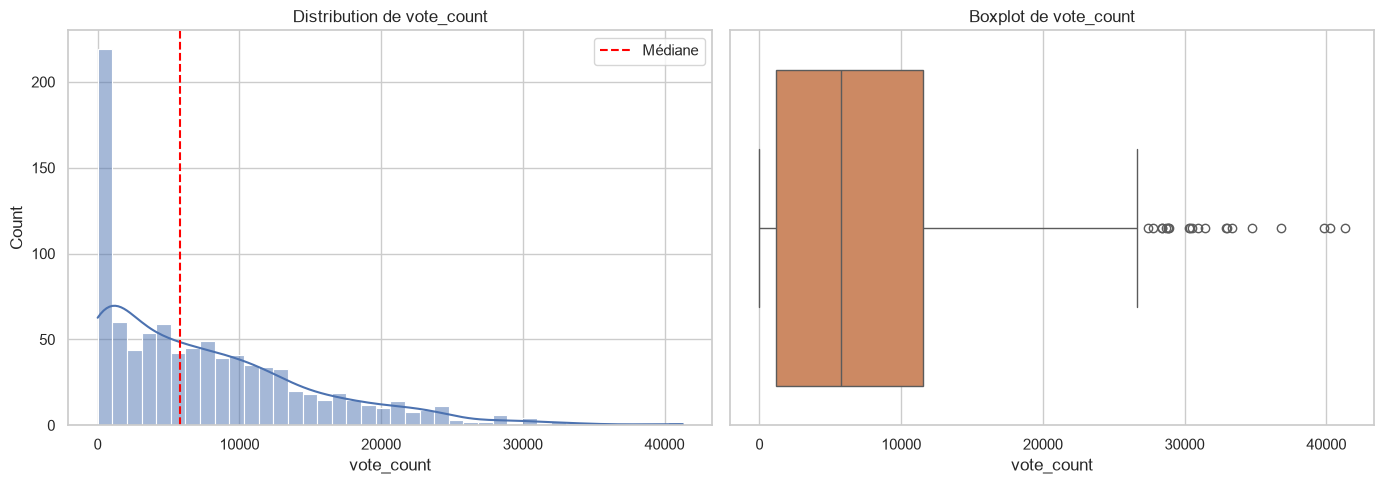

In [4]:
print(df["vote_count"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["vote_count"].dropna(), bins=40, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(df["vote_count"].median(), color="red", linestyle="--", label="Médiane")
axes[0].set_title("Distribution de vote_count")
axes[0].legend()

sns.boxplot(x=df["vote_count"].dropna(), ax=axes[1], color="#DD8452")
axes[1].set_title("Boxplot de vote_count")

plt.tight_layout()
plt.show()


In [8]:
vote_count_median = df["vote_count"].median()
print(f"Seuil retenu (médiane) : {vote_count_median:.0f} votes")

df = df[df["vote_count"].notna()].copy()

df["high_engagement"] = (df["vote_count"] > vote_count_median).astype(int)

print(df["high_engagement"].value_counts(normalize=True).rename("proportion"))


Seuil retenu (médiane) : 5777 votes
high_engagement
0    0.500537
1    0.499463
Name: proportion, dtype: float64


## 3. Exclusion des colonnes à risque de leakage



In [ ]:
leakage_columns = ["vote_count"]
identifier_columns = ["movie_id", "title"]

feature_columns = [
    c for c in df.columns
    if c not in leakage_columns + identifier_columns + ["high_engagement"]
]

print("Colonnes exclues (leakage) :", leakage_columns)
print("\nFeatures utilisées :", feature_columns)


Colonnes exclues (leakage) : ['vote_count', 'vote_average', 'popularity', 'revenue']

Features utilisées : ['budget', 'budget_category', 'has_keywords', 'is_holiday_release', 'is_original_language_en', 'is_summer_release', 'n_genres', 'n_keywords', 'overview_length', 'release_decade', 'release_month', 'release_year', 'runtime', 'runtime_category']


## 4. Split train/test

In [10]:
X = df[feature_columns]
y = df["high_engagement"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape[0]} films | Test : {X_test.shape[0]} films")
print("Répartition des classes (train) :")
print(y_train.value_counts(normalize=True))


Train : 744 films | Test : 187 films
Répartition des classes (train) :
high_engagement
1    0.5
0    0.5
Name: proportion, dtype: float64


## 5. Preprocessing avec `ColumnTransformer`




In [11]:
numeric_features = X.select_dtypes(include=["int64", "float64", "int32"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numériques :", numeric_features)
print("Catégorielles :", categorical_features)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


Numériques : ['budget', 'has_keywords', 'is_holiday_release', 'is_original_language_en', 'is_summer_release', 'n_genres', 'n_keywords', 'overview_length', 'release_decade', 'release_month', 'release_year', 'runtime']
Catégorielles : ['budget_category', 'runtime_category']


C:\Users\oussa\AppData\Local\Temp\ipykernel_14524\1594677578.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


## 6. Définition des 3 modèles (pipelines complets)

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "Linear SVM": LinearSVC(random_state=42, max_iter=5000),
}

pipelines = {
    name: Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])
    for name, model in models.items()
}


## 7. Entraînement et évaluation




In [13]:
def get_scores(pipeline, X_test):
    if hasattr(pipeline, "predict_proba"):
        return pipeline.predict_proba(X_test)[:, 1]
    return pipeline.decision_function(X_test)

results = []
predictions = {}
scores = {}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    y_score = get_scores(pipeline, X_test)

    predictions[name] = y_pred
    scores[name] = y_score

    results.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_score),
    })

results_df = pd.DataFrame(results).set_index("Modèle").round(3)
results_df


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modèle,,,,,
Logistic Regression,0.695,0.676,0.742,0.708,0.764
Random Forest,0.679,0.660,0.731,0.694,0.736
Linear SVM,0.695,0.680,0.731,0.705,0.764


## 8. Comparaison visuelle des métriques

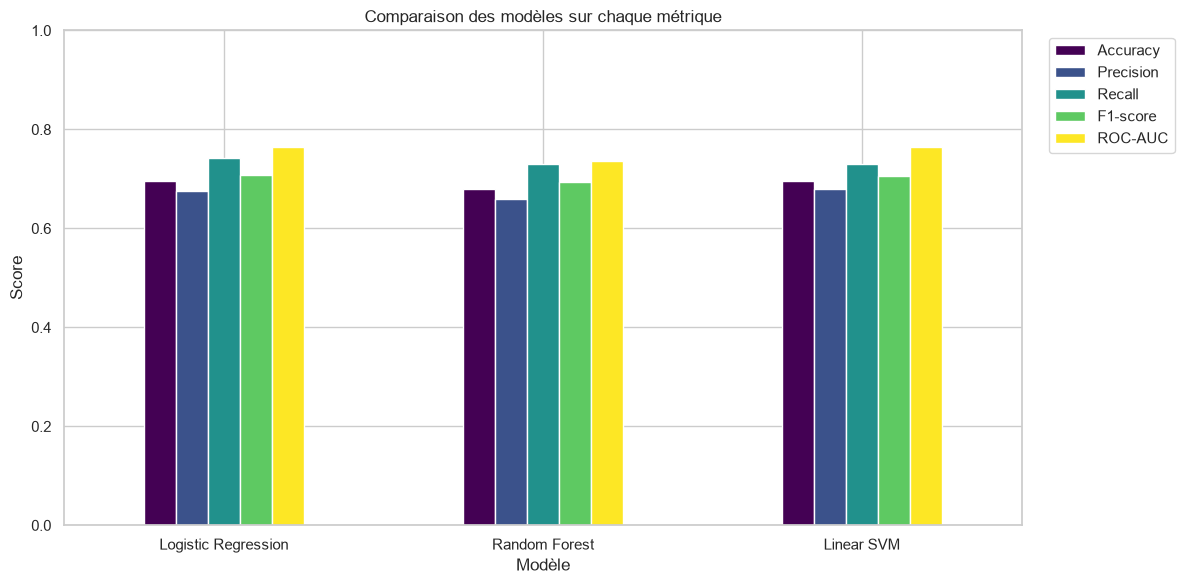

In [14]:
results_df.plot(kind="bar", figsize=(12, 6), colormap="viridis")
plt.title("Comparaison des modèles sur chaque métrique")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 9. Matrices de confusion

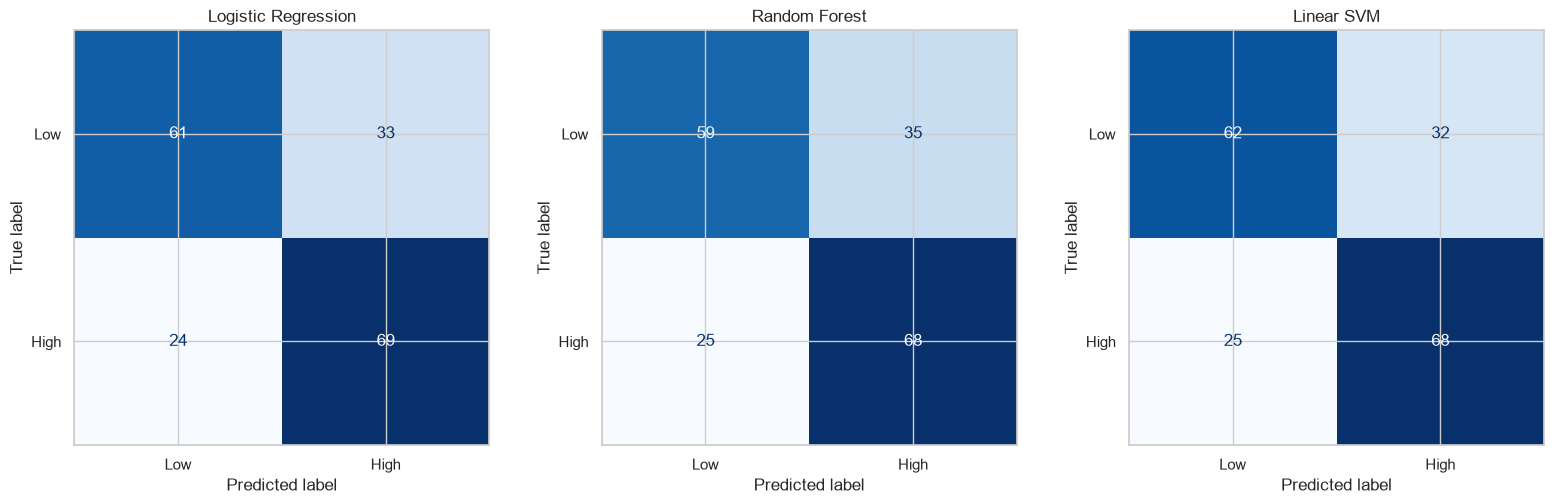

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Low", "High"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()


## 10. Courbes ROC

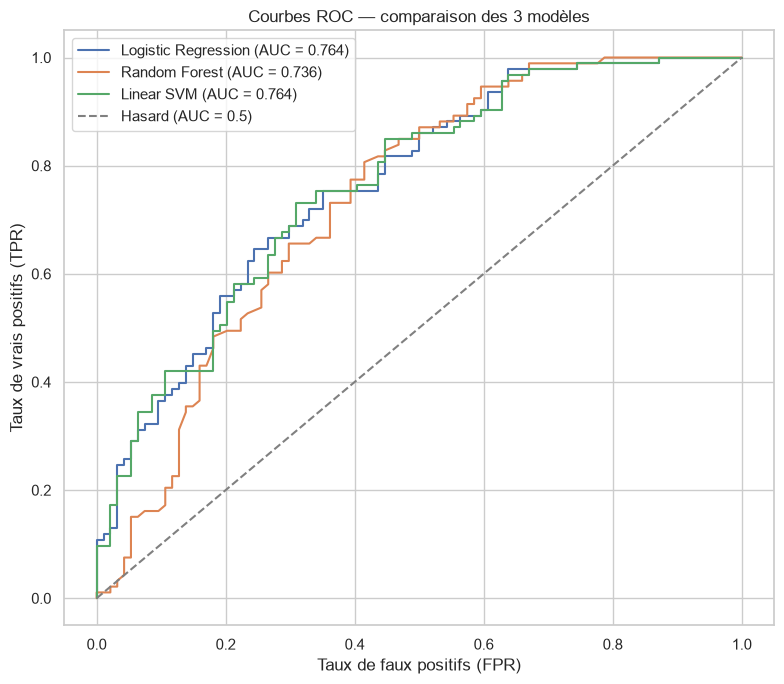

In [16]:
plt.figure(figsize=(8, 7))

for name, y_score in scores.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Hasard (AUC = 0.5)")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbes ROC — comparaison des 3 modèles")
plt.legend()
plt.tight_layout()
plt.show()
